# Retail Next Best Action (NBA): causal uplift + margin-aware decisioning

End-to-end walkthrough on a synthetic omnichannel apparel & footwear retailer. Instead of predicting *who will buy anyway*,
we estimate **incremental** margin and unsubscribe risk per `(customer, action)` with a multi-treatment DR-Learner (LightGBM),
pick the action with the best **net value**, enforce retail guardrails, and validate counterfactually on holdout logs.

| Action | Treatment |
|---|---|
| 0 | Holdout / no action |
| 1 | Email: new arrivals & back-in-stock (zero cost) |
| 2 | Push: free express shipping ($8) |
| 3 | Email+SMS: 15% off (margin erosion) |
| 4 | App: 2x loyalty points (deferred liability) |

`NetValue(x,a) = tau_margin(x,a) - Cost(a) - lambda * tau_unsub(x,a)`

The reusable code lives in the `nba/` package; this notebook runs each module and shows its outputs inline (PNGs are also saved under `outputs/`).

## 0. Setup

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from nba.config import *
from nba.artifact_manager import ArtifactManager
from nba import data_plots, eval_plots
from nba.synthetic_data import make_dataset
from nba.schemas import validate_log_frame
from nba.uplift_model import fit_uplift_bundle, save_bundle, update_manifest
from nba.policy import decide
from nba.evaluation import *

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
N_CUSTOMERS = 100_000

## 1. Output directory & artifact manager

In [2]:
am = ArtifactManager()   # creates outputs/{data_plots,validation_plots,comparison_plots,saved_models}
print(am.root)
print(sorted(p.name for p in am.root.iterdir()))

D:\Ramakrishna_D\Python\GitProjects\machinelearning\Next-Best-Action_NBA\outputs
['api_request_response.png', 'comparison_plots', 'data_plots', 'decision_log.jsonl', 'saved_models', 'validation_plots']


## 2. Off-policy log, point-in-time features, data diagnostics

Synthetic world: latent segments (full-price loyalists, discount hunters, at-risk, mainstream), a *stochastic legacy CRM* logging policy
mixed with **5% epsilon exploration** (so propensities are logged and positivity holds), and **delayed rewards**: purchase counted within a 7-day window,
returns netted within 30 days; rows whose windows have not closed (`reward_mature=False`) are excluded from training. Shoppers with <2 sessions are **cold-start**.

In [3]:
ds = make_dataset(N_CUSTOMERS, SEED)
n_ok = validate_log_frame(ds.log.assign(**ds.x.reset_index(drop=True)), FEATURE_COLUMNS)
print(f"{len(ds.log):,} logged decisions | {n_ok} schema-validated | mature rewards {ds.log['reward_mature'].mean():.1%} "
      f"| cold-start {ds.x['is_cold_start'].mean():.1%} | train/holdout {len(ds.train_idx):,}/{len(ds.test_idx):,}")
ds.log.drop(columns=[c for c in ds.log.columns if c.startswith(('truth_', 'logp_'))]).head()

100,000 logged decisions | 2000 schema-validated | mature rewards 80.7% | cold-start 7.9% | train/holdout 56,520/24,223


,customer_id,timestamp,action_id,propensity_score,incremental_revenue,gross_margin_dollars,returned_flag,purchased_flag,unsubscribed_flag,reward_mature,promos_last_7d,net_margin_30d
0,0,2026-05-04 15:40:16.849232144,3,0.200,0.000000,0.000000,False,False,False,True,0,-0.500000
1,1,2026-06-11 16:14:00.048248397,0,0.105,0.000000,0.000000,False,False,False,False,1,0.000000
2,2,2026-03-30 14:23:03.507271527,0,0.105,0.000000,0.000000,False,False,False,True,2,0.000000
3,3,2026-02-15 12:06:47.738641822,3,0.580,0.000000,0.000000,False,False,False,True,0,-0.500000
4,4,2026-02-21 08:56:47.120309607,2,0.200,57.873604,28.936802,False,True,False,True,2,20.936802


In [4]:
print("Arm sizes (mature rows):"); print(ds.log.iloc[ds.train_idx]["action_id"].map(ACTION_SHORT).value_counts().sort_index())
ds.x.describe().T[["mean", "std", "min", "max"]].round(2)

Arm sizes (mature rows):
action_id
A0 Holdout        7301
A1 Email Recs    13052
A2 Free Ship      7808
A3 15% Off       21542
A4 2x Points      6817
Name: count, dtype: int64


,mean,std,min,max
recency_days,83.30,76.43,1.00,364.98
freq_30d,0.39,0.69,0.00,6.00
freq_90d,1.20,1.41,0.00,11.00
freq_365d,5.47,3.82,0.00,33.00
monetary_30d,36.92,72.93,0.00,932.07
monetary_90d,112.93,152.41,0.00,1660.07
monetary_365d,509.30,439.42,0.00,4495.13
aov_365d,89.65,28.41,9.35,342.71
markdown_share,0.44,0.36,0.00,1.00
discount_tier,0.94,0.85,0.00,2.00


treatment_propensity_overlap.png


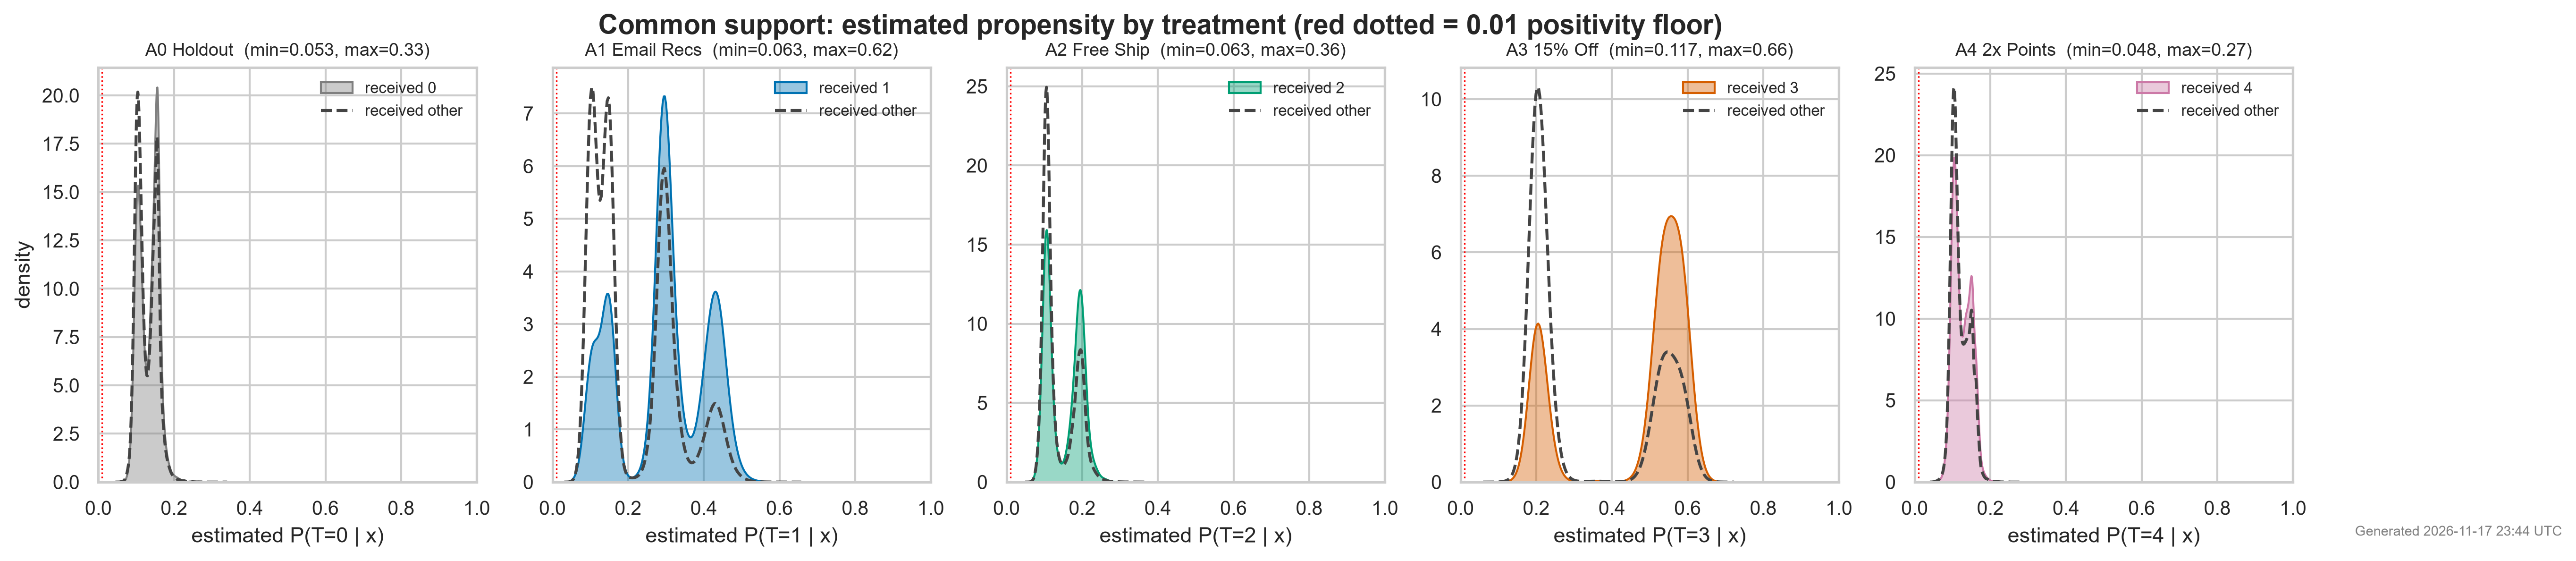

feature_correlations_and_drift.png


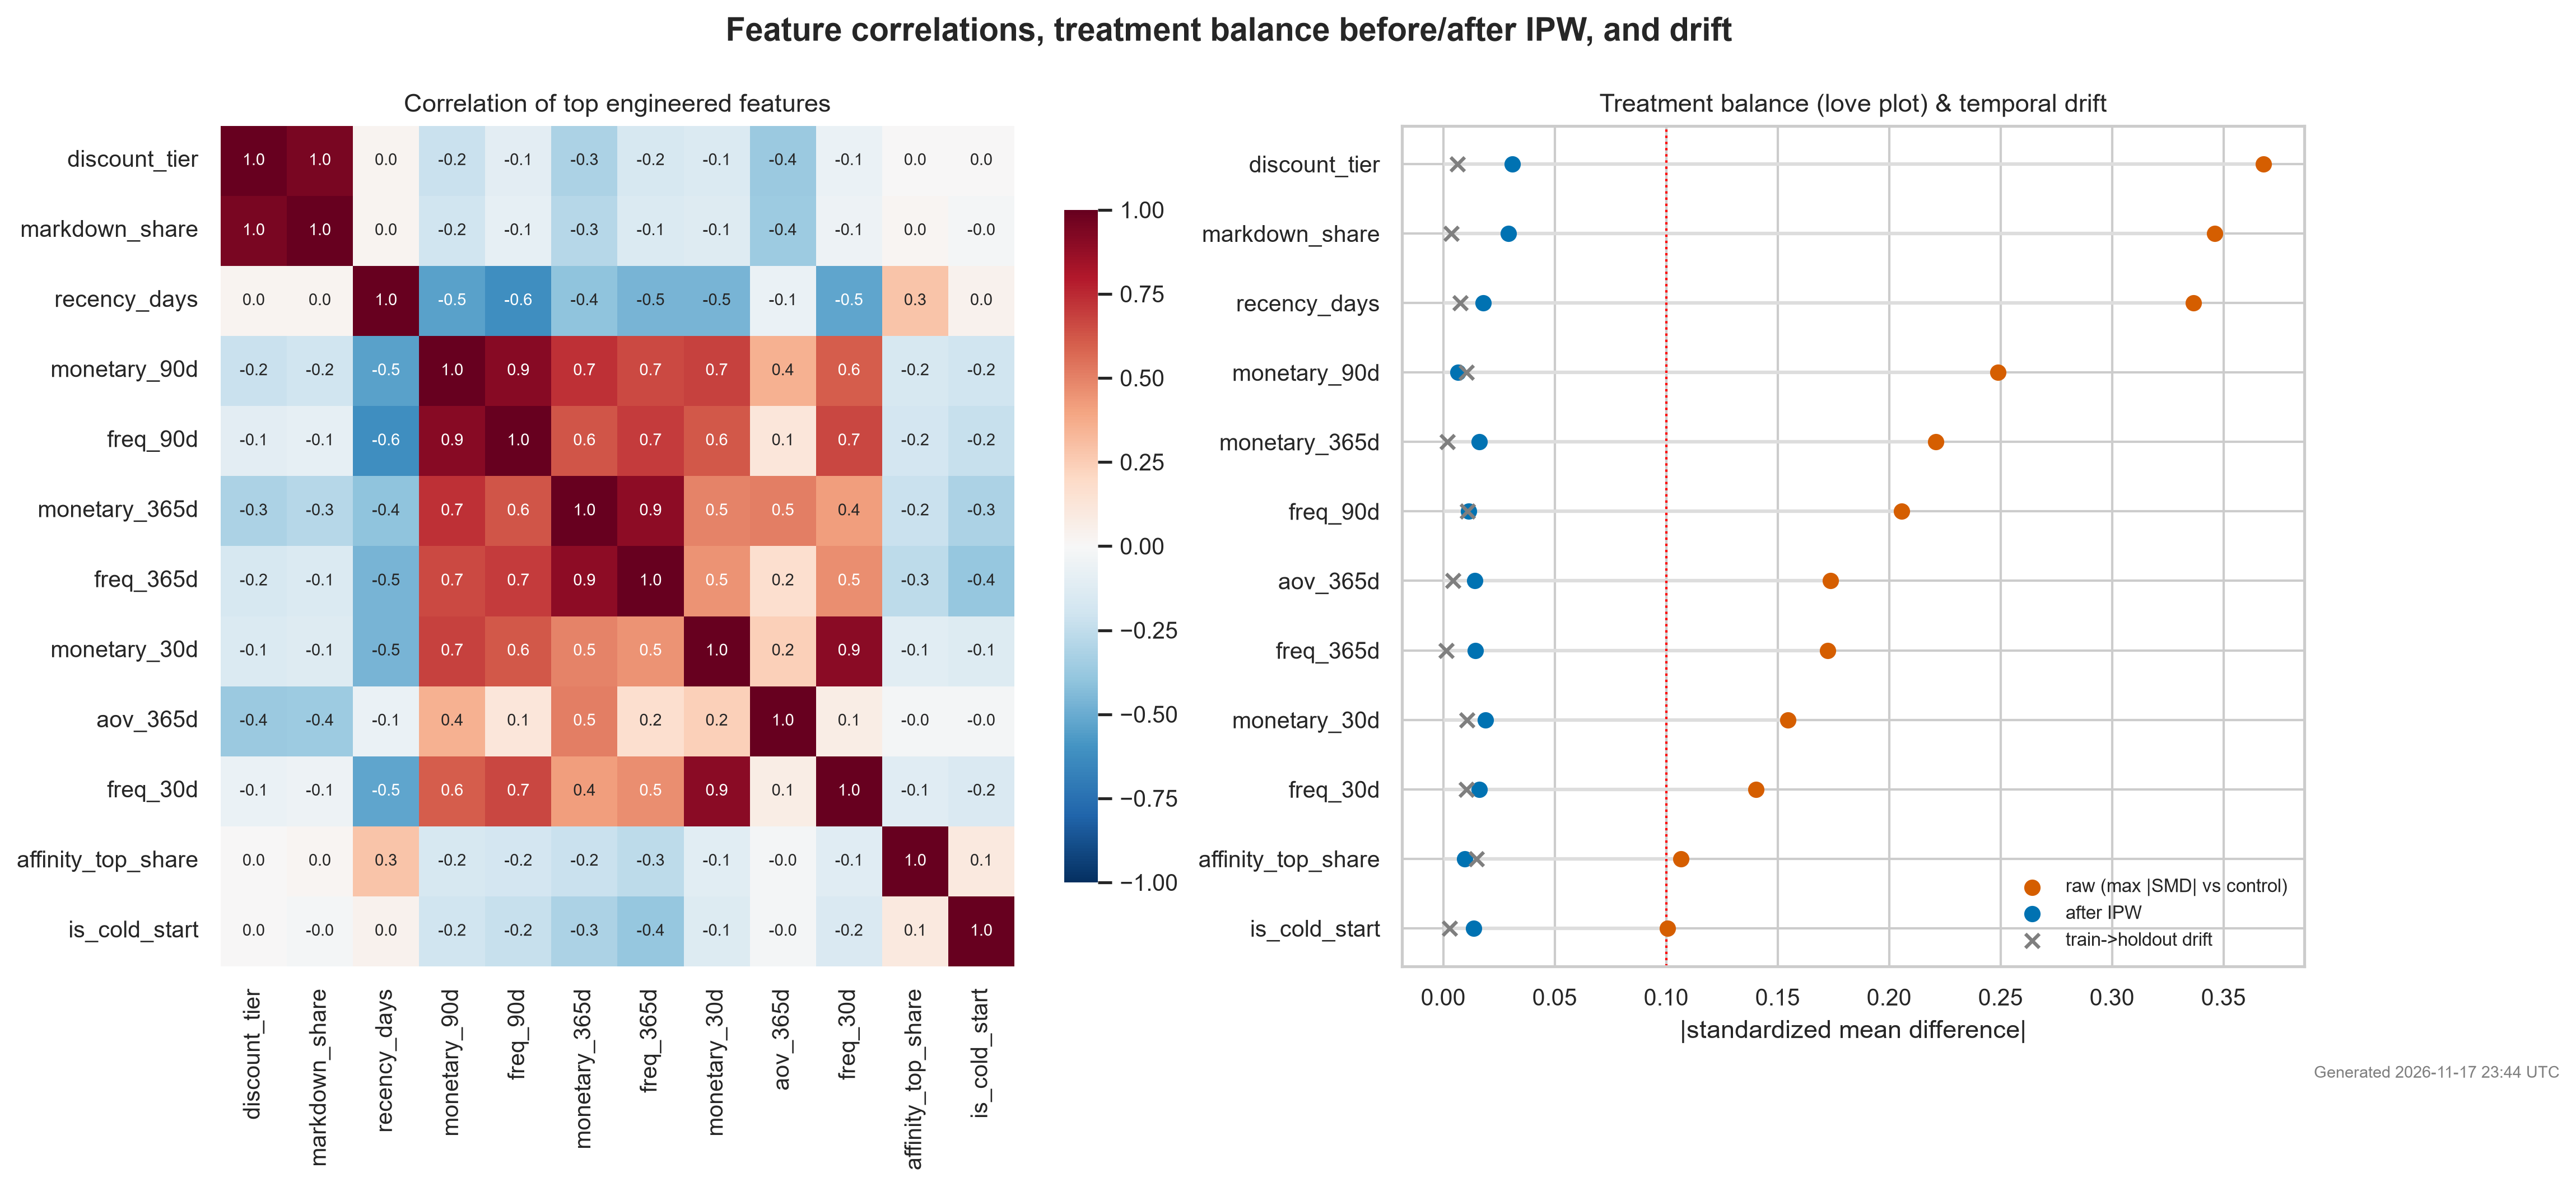

margin_and_return_distributions.png


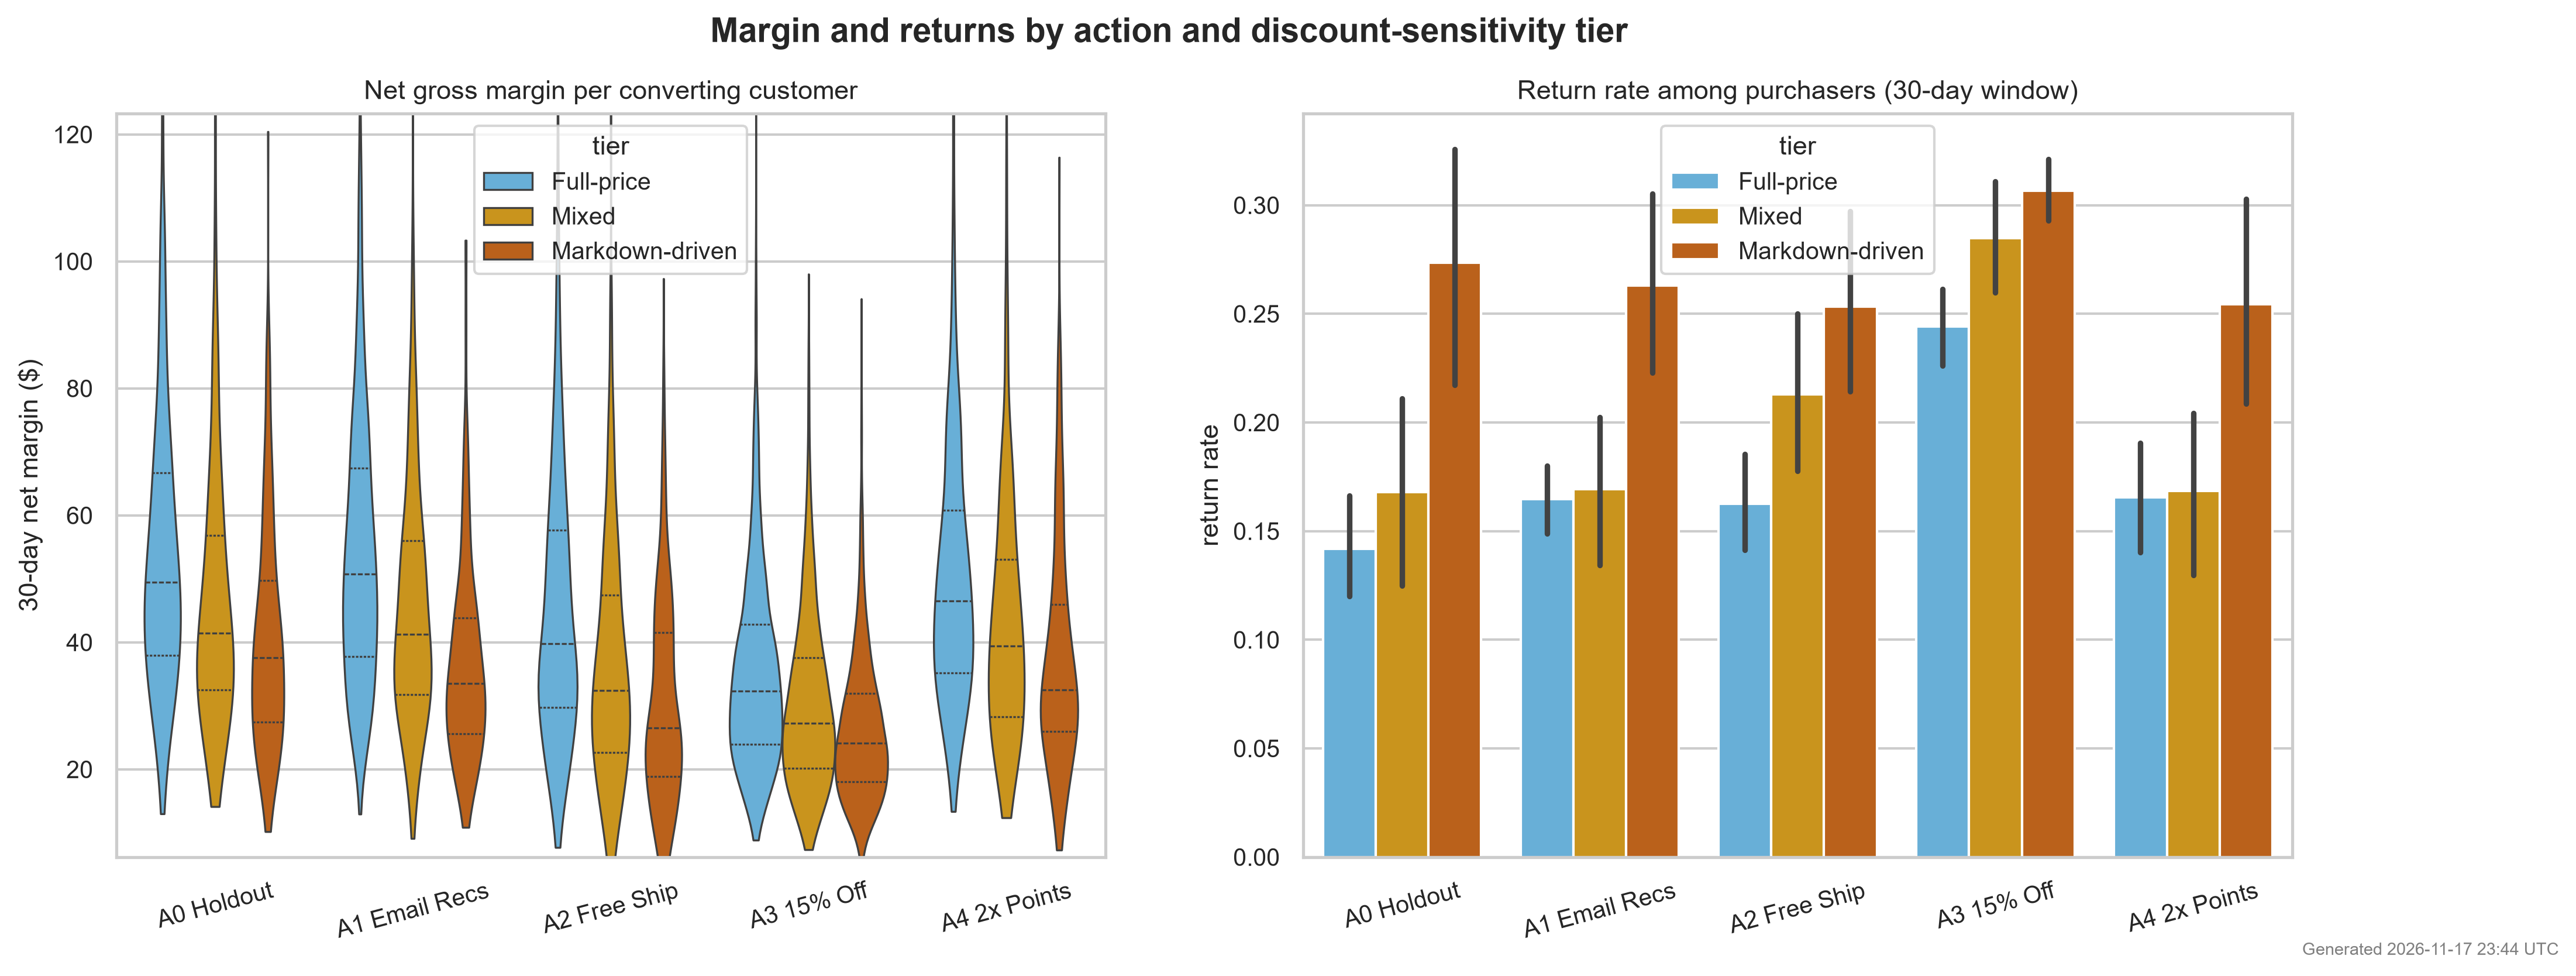

In [5]:
m_idx = np.sort(np.concatenate([ds.train_idx, ds.test_idx]))
xm, lm = ds.x.iloc[m_idx].reset_index(drop=True), ds.log.iloc[m_idx].reset_index(drop=True)
is_test = np.isin(m_idx, ds.test_idx)
tier = ds.raw_features["discount_tier"].fillna(1).iloc[m_idx].to_numpy()

p1 = data_plots.plot_propensity_overlap(am, xm, lm["action_id"].to_numpy())
p2 = data_plots.plot_correlations_and_drift(am, xm, lm["action_id"].to_numpy(), lm["propensity_score"].to_numpy(), is_test)
p3 = data_plots.plot_margin_and_returns(am, lm, tier)
for p in (p1, p2, p3):
    print(p.name); display(Image(filename=str(p), width=1000))

## 3. Multi-treatment causal uplift models

Two `econml.DRLearner`s (LightGBM propensity, outcome and final stages, cross-fitted, control = action 0): one for gross margin, one for unsubscribe.
Cold-start CATEs are shrunk toward the global ATE. Models + feature transformer are serialized with `joblib`; `model_manifest.json` records timestamp, feature order, costs, lambda and CV metrics.

In [6]:
x_tr, l_tr = ds.x.iloc[ds.train_idx].reset_index(drop=True), ds.log.iloc[ds.train_idx].reset_index(drop=True)
x_te, l_te = ds.x.iloc[ds.test_idx].reset_index(drop=True), ds.log.iloc[ds.test_idx].reset_index(drop=True)
bundle = fit_uplift_bundle(x_tr, l_tr, ds.transformer, SEED)
save_bundle(bundle, am, DEFAULT_LAMBDA)
print("CV metrics:", {k: round(v, 3) for k, v in bundle.cv_metrics.items()})

[uplift] fitting on 56,520 mature rows; arm sizes: {np.int64(0): np.int64(7301), np.int64(1): np.int64(13052), np.int64(2): np.int64(7808), np.int64(3): np.int64(21542), np.int64(4): np.int64(6817)}


CV metrics: {'propensity_logloss': 1.422, 'propensity_auc_ovr': 0.611, 'margin_outcome_r2': 0.055, 'unsub_outcome_auc': 0.702, 'cv_folds': 3}


In [7]:
tm, tu = bundle.predict_tau(x_te.to_numpy(dtype=np.float32))
truth = l_te[[f"truth_tau_margin_a{a}" for a in TREATMENT_IDS]].to_numpy()   # known only because data is synthetic
rec = pd.DataFrame({"corr(pred, true CATE)": [np.corrcoef(tm[:, j], truth[:, j])[0, 1] for j in range(4)],
                    "mean predicted tau_margin ($)": tm.mean(0), "mean true tau_margin ($)": truth.mean(0),
                    "mean predicted tau_unsub": tu.mean(0)}, index=[ACTION_SHORT[a] for a in TREATMENT_IDS]).round(3)
rec

,"corr(pred, true CATE)",mean predicted tau_margin ($),mean true tau_margin ($),mean predicted tau_unsub
A1 Email Recs,0.010,0.640,0.447,0.001
A2 Free Ship,0.082,1.771,1.590,0.001
A3 15% Off,0.510,0.715,0.715,0.014
A4 2x Points,0.077,1.193,1.147,-0.001


**Epsilon-greedy exploration** logs the exact probability of each randomized choice so future data stays unbiased for IPW:

In [8]:
from nba.exploration import EpsilonGreedyPolicy
pol = EpsilonGreedyPolicy(0.05, seed=0)
elig = np.ones((5, 5), bool); elig[0, 2] = False
acts, prop, expl = pol.select(np.full(5, 3), elig)
pd.DataFrame({"chosen": acts, "logged_propensity": prop.round(4), "explored": expl})

,chosen,logged_propensity,explored
0,3,0.9625,False
1,3,0.9600,False
2,3,0.9600,True
3,2,0.0100,True
4,3,0.9600,False


## 4. Margin-aware policy and retail guardrails

Hard rules applied before the argmax: **margin protection** (no 15%-off for Sure Things or full-price loyalists), **contact-fatigue cap** (max 2 promos / rolling 7 days),
**inventory** (no A1 if top-affinity category has <20% size availability), plus **cold-start** restriction (no discounting for guests). Offline the fatigue count comes from the logged
`promos_last_7d`; online it is read from Redis (not used in this notebook).

In [9]:
d_free = decide(bundle, x_te, l_te["promos_last_7d"].to_numpy(), lam=DEFAULT_LAMBDA, use_guardrails=False)
d_guard = decide(bundle, x_te, l_te["promos_last_7d"].to_numpy(), lam=DEFAULT_LAMBDA)
cmp = pd.DataFrame({"no guardrails": pd.Series(d_free.actions).map(ACTION_SHORT).value_counts(normalize=True),
                    "with guardrails": pd.Series(d_guard.actions).map(ACTION_SHORT).value_counts(normalize=True)}).fillna(0).round(3)
cmp

,no guardrails,with guardrails
A1 Email Recs,0.572,0.552
A0 Holdout,0.185,0.240
A3 15% Off,0.170,0.142
A4 2x Points,0.065,0.057
A2 Free Ship,0.009,0.008


In [10]:
# What did each guardrail block? (share of holdout customers for whom the rule suppressed the action)
rows = {rule: m.mean(axis=0) for rule, m in d_guard.guardrails.blocked_by.items()}
pd.DataFrame(rows, index=[ACTION_SHORT[a] for a in ACTION_IDS]).T.round(3)

,A0 Holdout,A1 Email Recs,A2 Free Ship,A3 15% Off,A4 2x Points
margin_protection,0.0,0.000,0.000,0.364,0.000
contact_fatigue,0.0,0.000,0.156,0.156,0.156
inventory,0.0,0.102,0.000,0.000,0.000
cold_start,0.0,0.000,0.079,0.079,0.000


## 5. Counterfactual validation & policy comparison (holdout)

Policies are evaluated with **SNIPS** (self-normalised importance sampling) using logged propensities, with 95% bootstrap CIs. The Qini/decile checks use IPW-adjusted incremental margin.

qini_and_uplift_curves


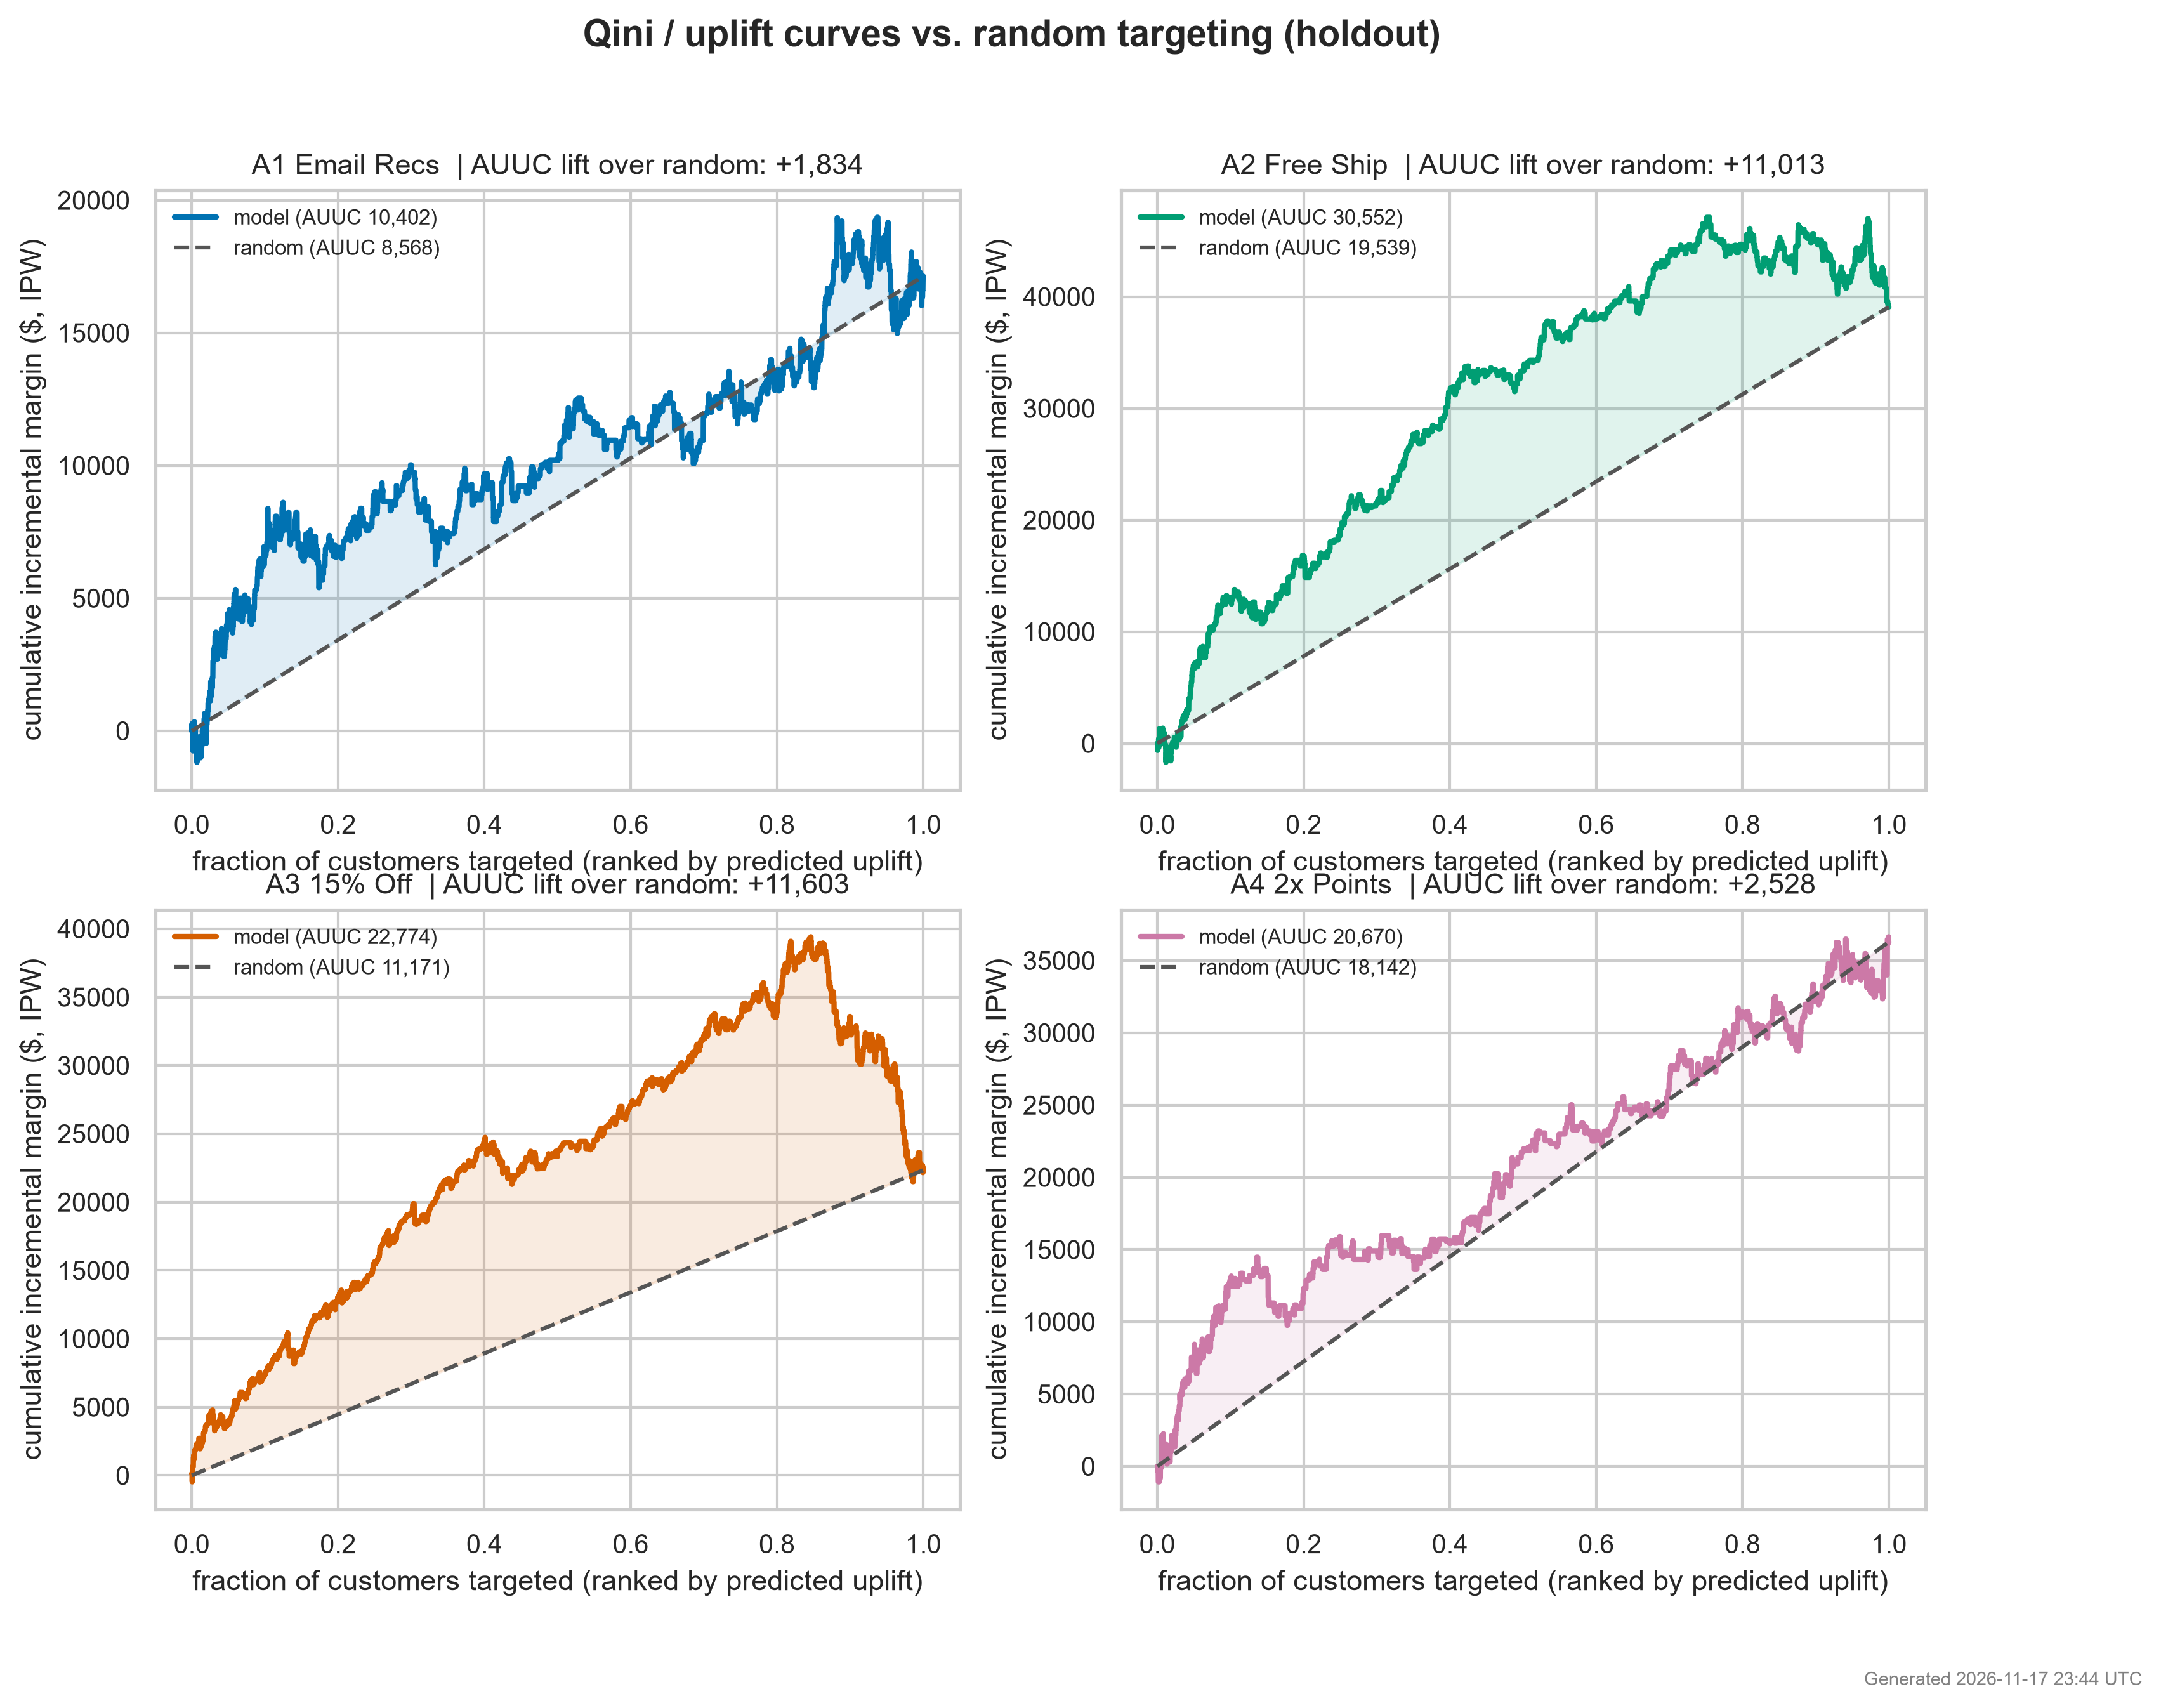

cate_calibration_by_decile


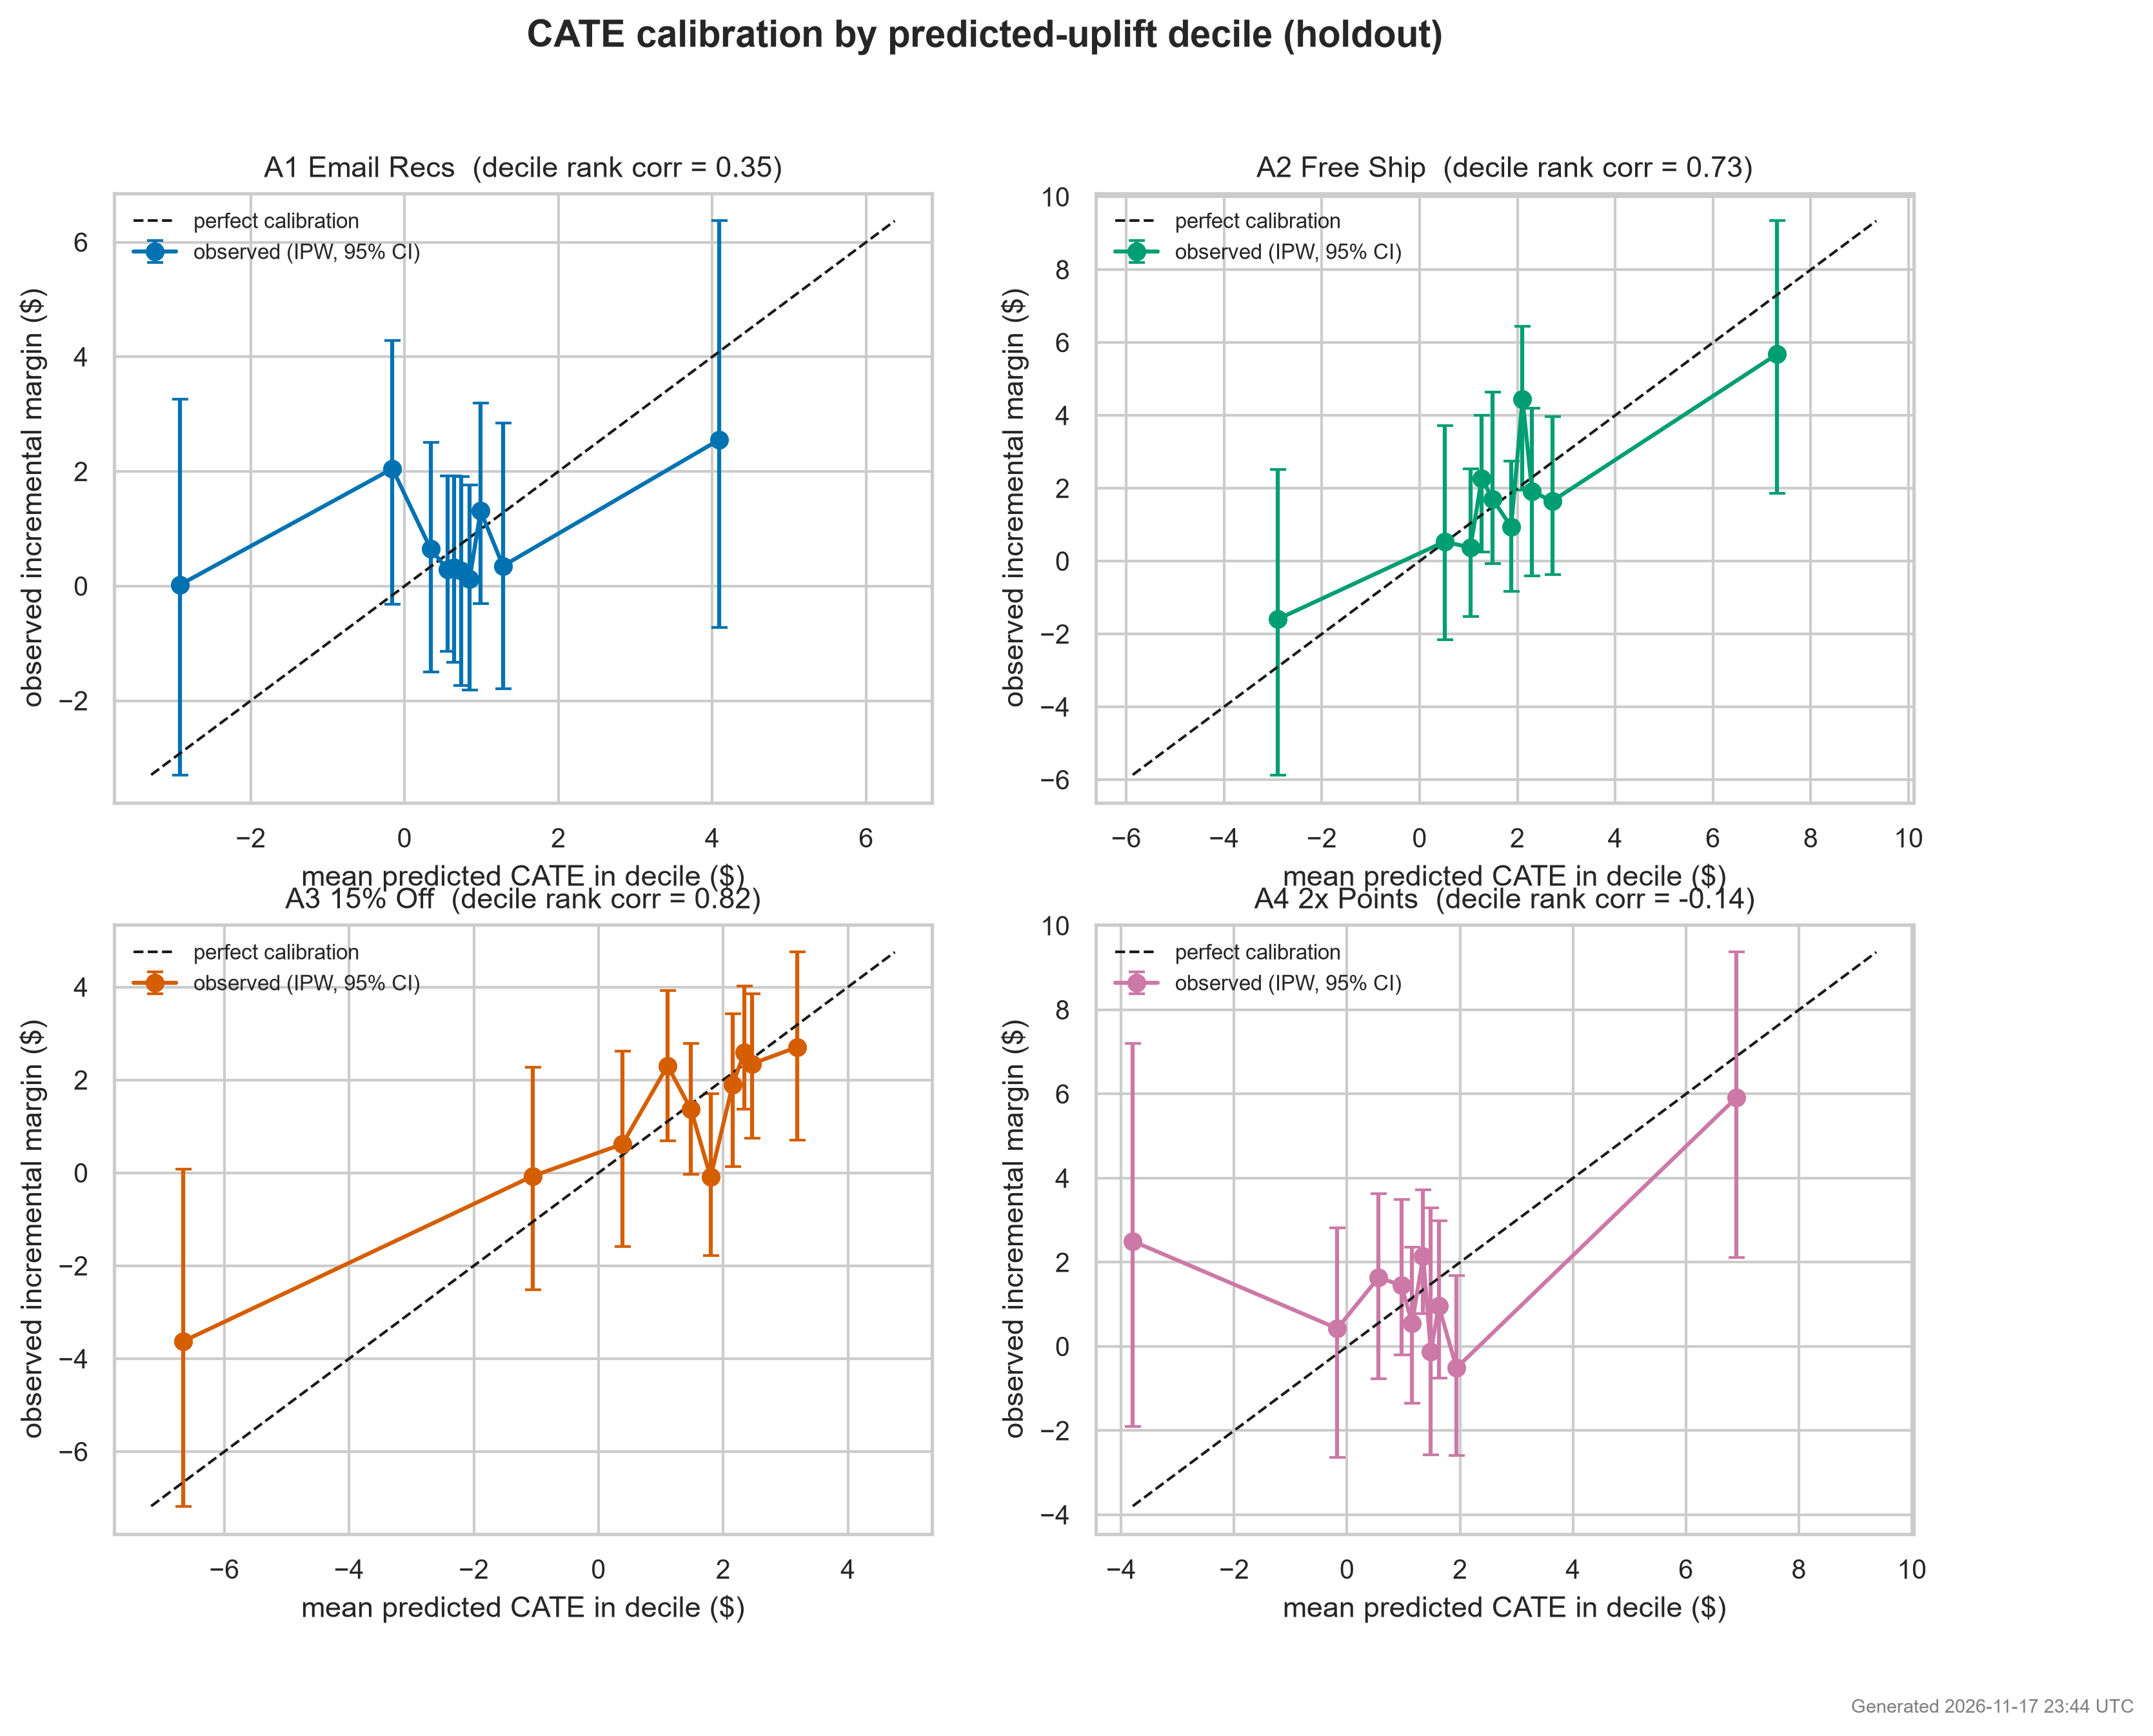

nuisance_model_diagnostics


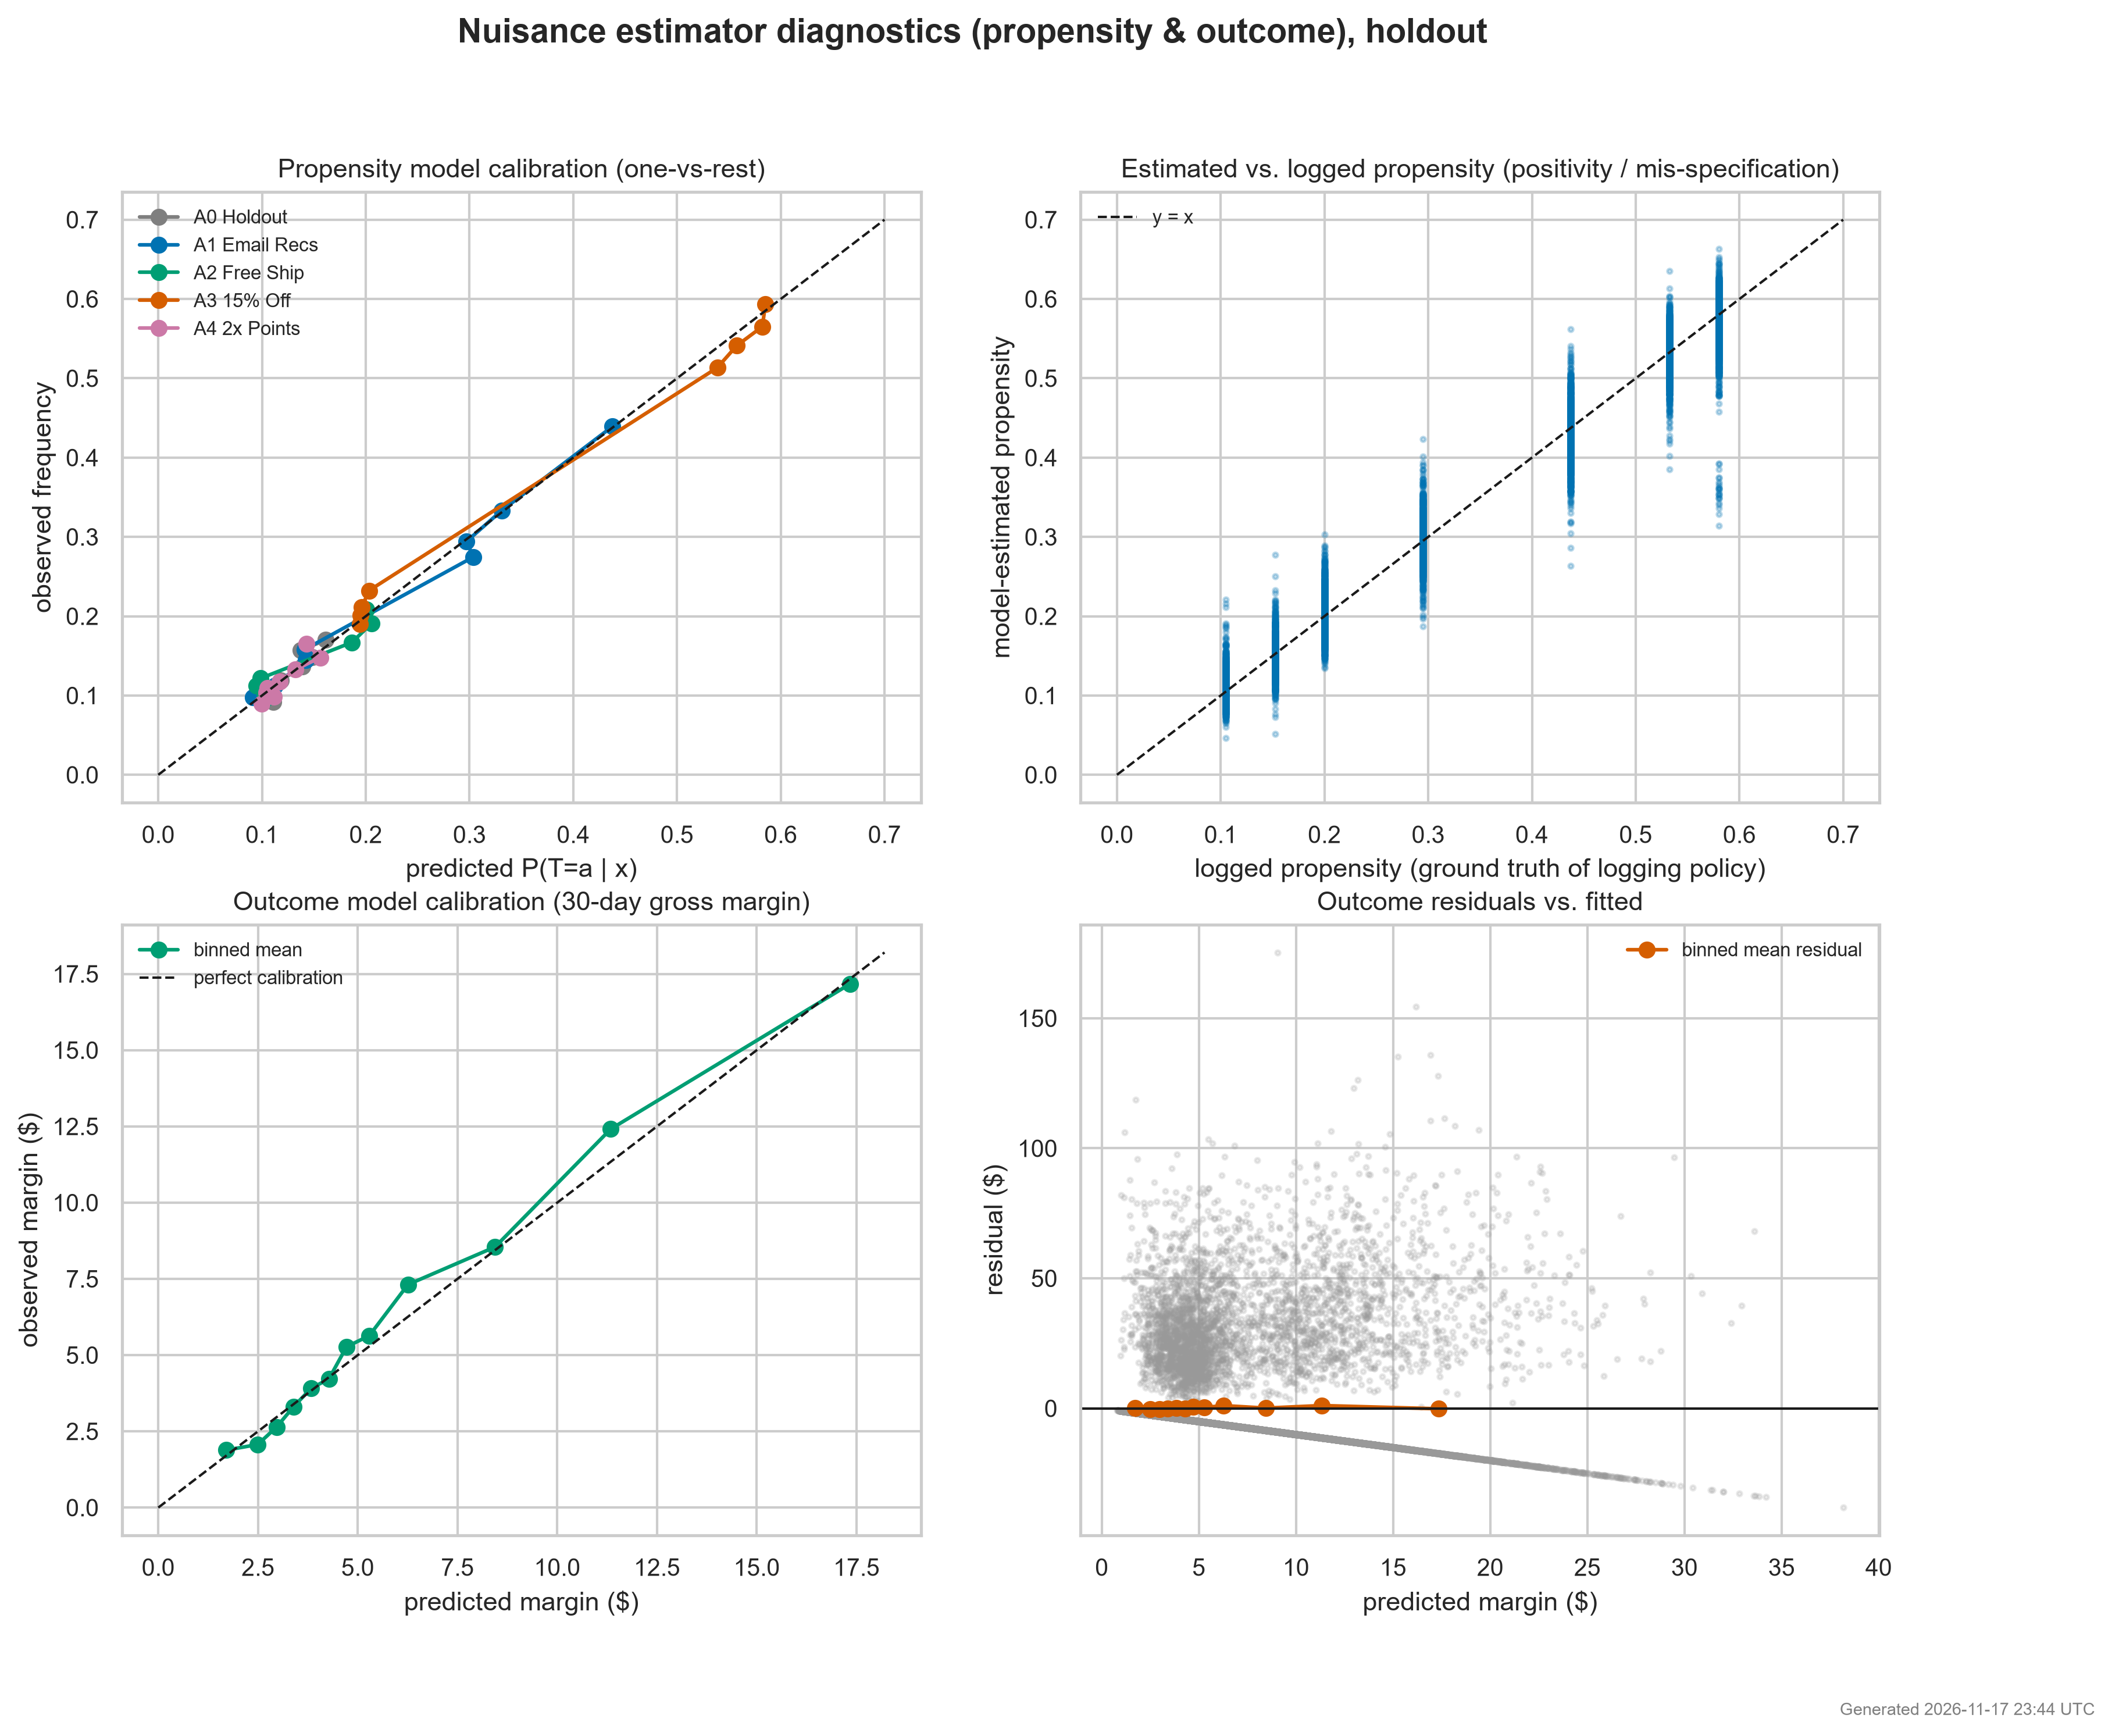

{'auuc_lift_a1': 1833.786, 'auuc_lift_a2': 11013.052, 'auuc_lift_a3': 11602.756, 'auuc_lift_a4': 2527.587, 'decile_spearman_a1': 0.345, 'decile_spearman_a2': 0.733, 'decile_spearman_a3': 0.818, 'decile_spearman_a4': -0.139}


In [11]:
_, qini = eval_plots.plot_qini(am, l_te, tm)
_, calib = eval_plots.plot_cate_calibration(am, l_te, tm)
p_n = eval_plots.plot_nuisance_diagnostics(am, x_tr, l_tr, x_te, l_te, SEED)
for name in ("qini_and_uplift_curves", "cate_calibration_by_decile", "nuisance_model_diagnostics"):
    print(name); display(Image(filename=str(am.dir("validation_plots") / f"{name}.png"), width=900))
print({k: round(v, 3) for k, v in {**qini, **calib}.items()})

In [12]:
sweep = lambda_sweep(bundle, x_te, l_te)
lam_star = select_lambda(sweep)
print(f"selected lambda = {lam_star:g} (smallest meeting the {UNSUB_RATE_CAP:.1%} unsubscribe cap)")
sweep.round(4)

selected lambda = 100 (smallest meeting the 0.5% unsubscribe cap)


,lambda,net_margin,ci_low,ci_high,unsub_rate,treat_rate,oracle
0,0,6.1228,5.6243,6.6364,0.0097,0.8579,0.6693
1,5,6.1311,5.6381,6.6408,0.0096,0.8562,0.6641
2,10,6.1544,5.6604,6.6712,0.0096,0.8545,0.6619
3,25,6.1169,5.6196,6.6233,0.0093,0.8485,0.6473
4,50,5.9535,5.4638,6.4915,0.0081,0.8295,0.5994
5,100,5.7641,5.2245,6.3079,0.0047,0.7596,0.4018
6,200,5.5273,4.9451,6.0822,0.0032,0.6666,0.2490
7,400,5.4765,4.9290,6.0531,0.0028,0.5962,0.1984
8,800,5.5551,4.9965,6.1116,0.0027,0.5399,0.1694
9,1600,5.4680,4.9112,6.0316,0.0026,0.4668,0.1332


In [13]:
a_log = l_te["action_id"].to_numpy()
nba = decide(bundle, x_te, l_te["promos_last_7d"].to_numpy(), lam=lam_star)
naive_model = fit_naive_propensity_model(x_tr, l_tr["purchased_flag"].to_numpy())
naive, uncon = naive_propensity_actions(naive_model, x_te), unconstrained_uplift_actions(bundle, x_te)
reports = [
    evaluate_policy("(a) Historical\nRule-Based CRM", l_te, legacy_policy_probs(x_te, a_log)),
    evaluate_policy("(b) Naive Propensity\nTargeting", l_te, deterministic_probs(naive, a_log), naive),
    evaluate_policy("(c) Unconstrained\nUplift Policy", l_te, deterministic_probs(uncon, a_log), uncon),
    evaluate_policy("(d) Guardrailed\nMargin-Aware NBA", l_te, deterministic_probs(nba.actions, a_log), nba.actions),
]
pd.DataFrame([{"policy": r.name.replace("\n", " "), "SNIPS net margin ($)": r.value, "CI low": r.ci_low, "CI high": r.ci_high,
               "ESS": r.ess, "oracle incremental ($, synthetic truth)": r.oracle_incremental} for r in reports]).round(2)

,policy,SNIPS net margin ($),CI low,CI high,ESS,"oracle incremental ($, synthetic truth)"
0,(a) Historical Rule-Based CRM,4.71,4.50,4.91,24200.36,NaN
1,(b) Naive Propensity Targeting,5.05,4.59,5.53,3804.81,-0.41
2,(c) Unconstrained Uplift Policy,3.93,3.33,4.50,4349.06,-1.77
3,(d) Guardrailed Margin-Aware NBA,5.76,5.22,6.31,4121.70,0.40


policy_net_margin_comparison


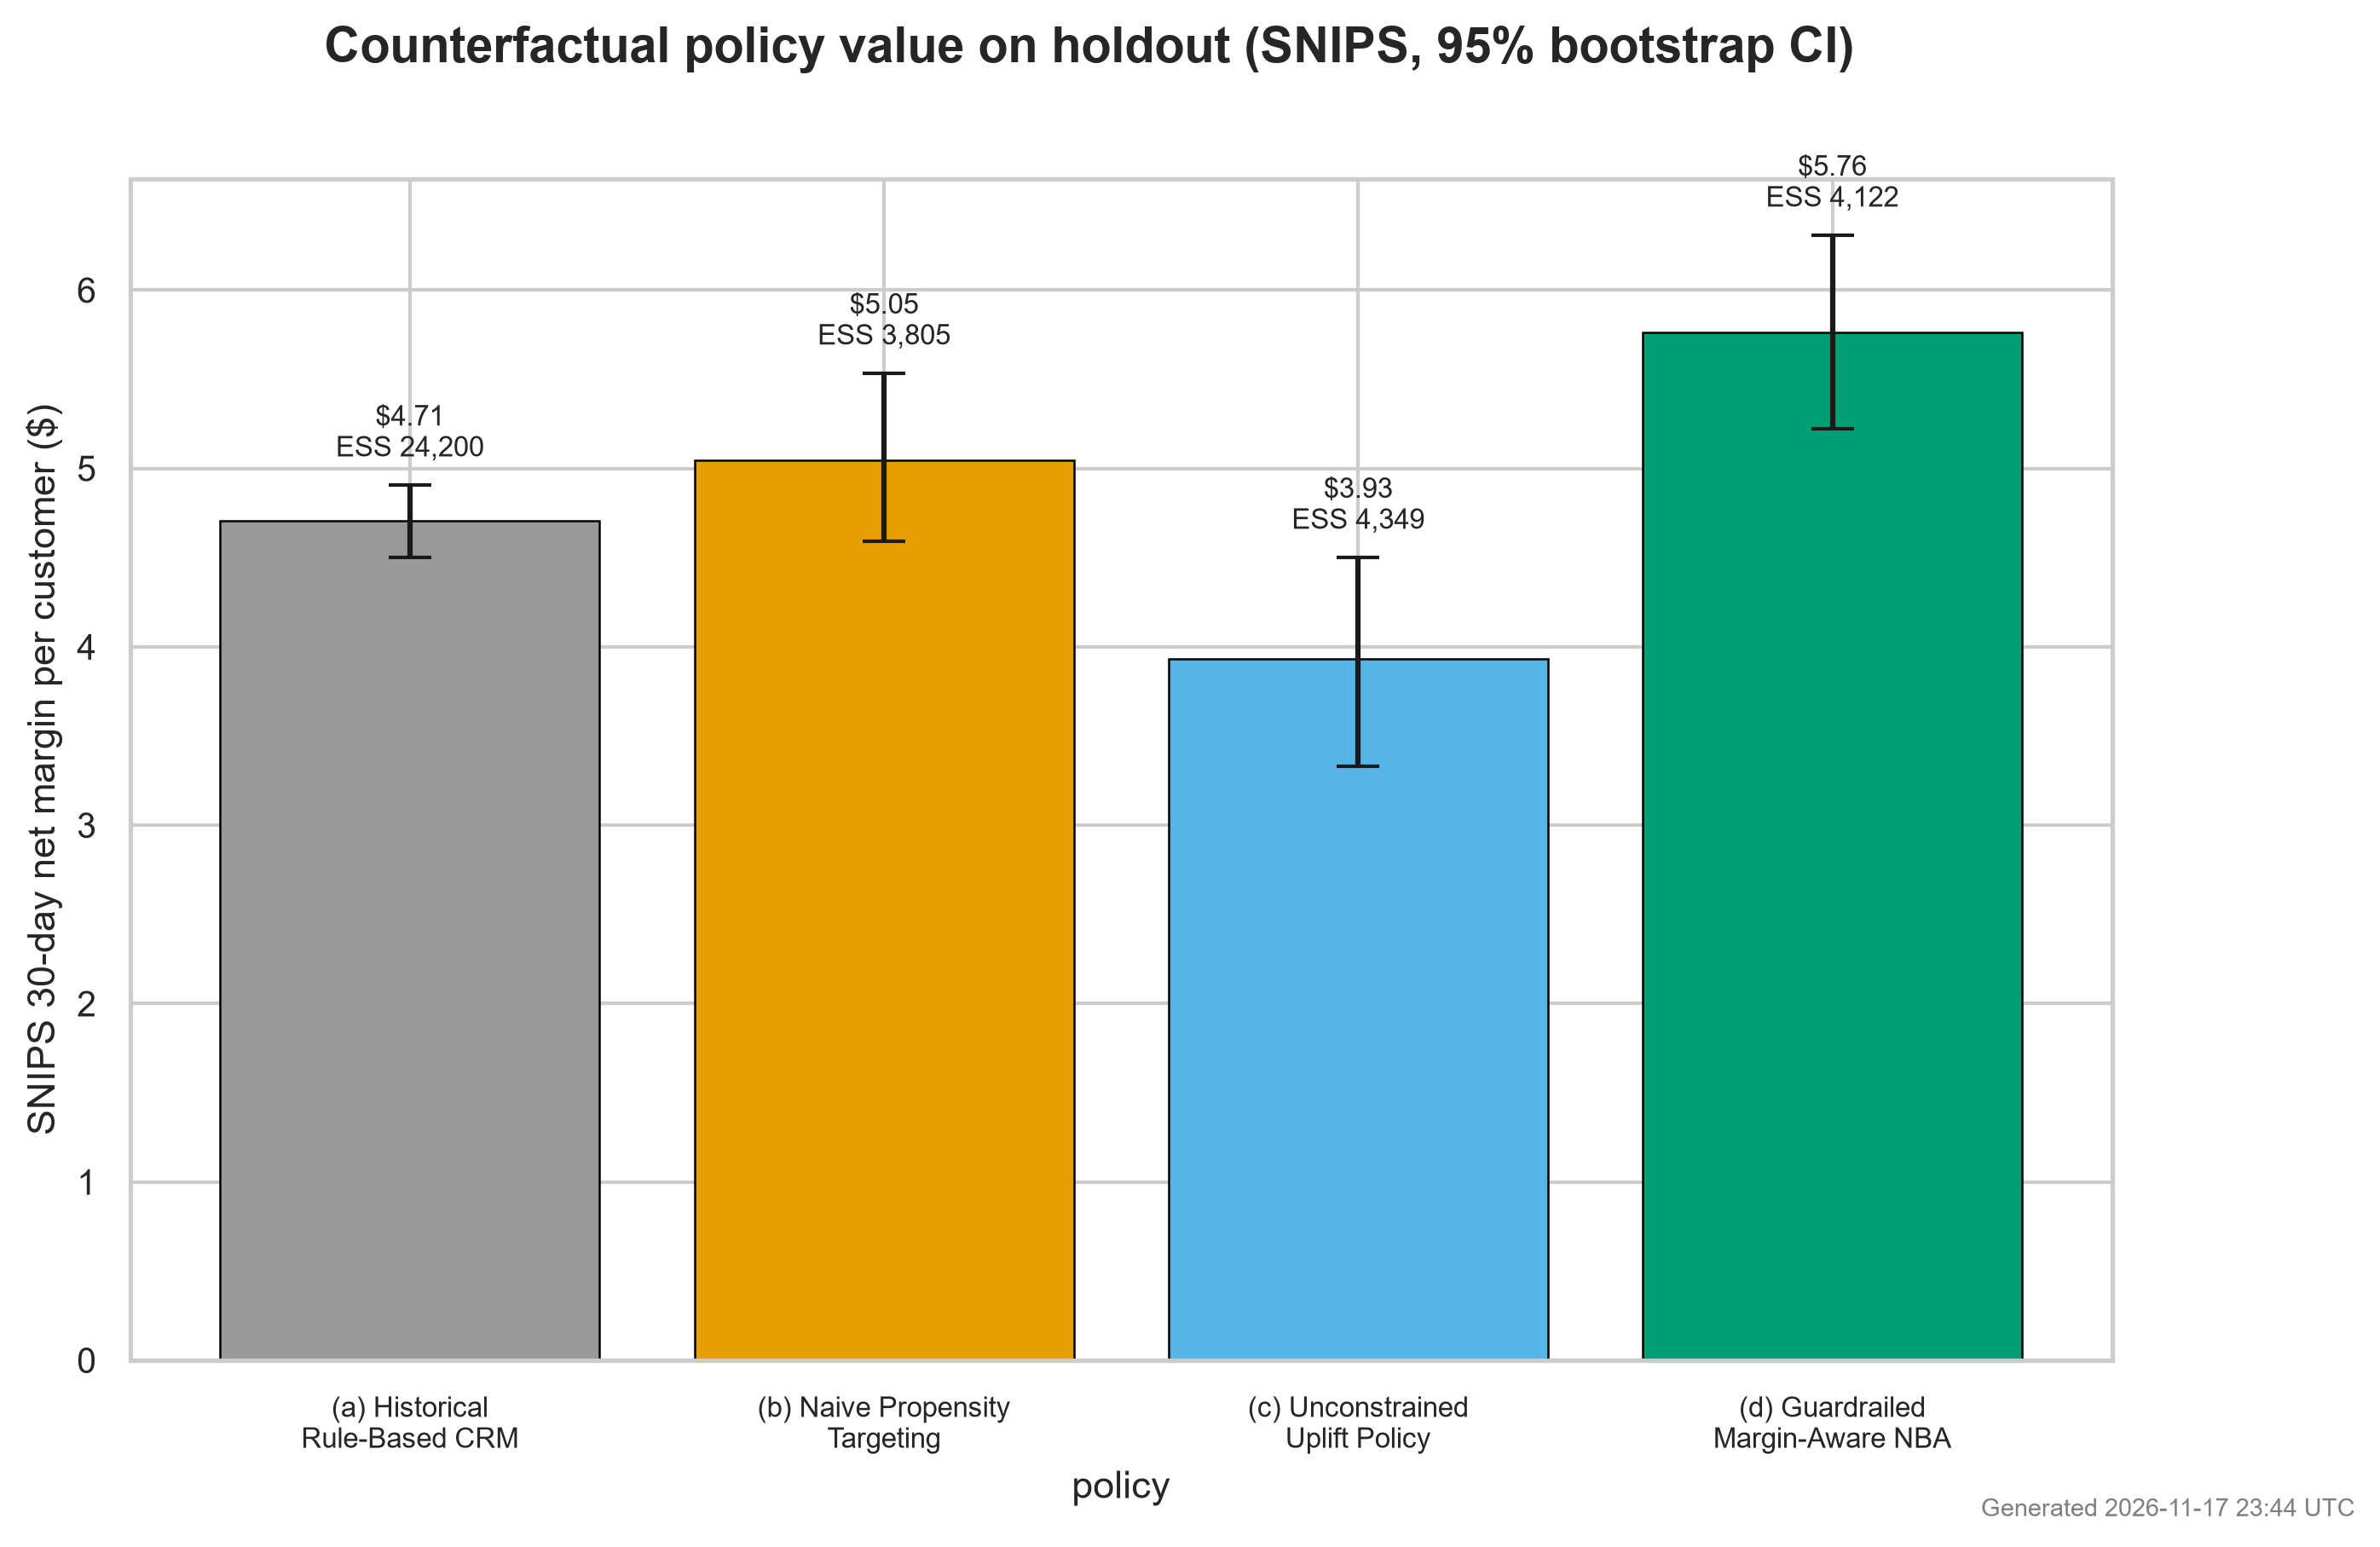

action_allocation_by_segment


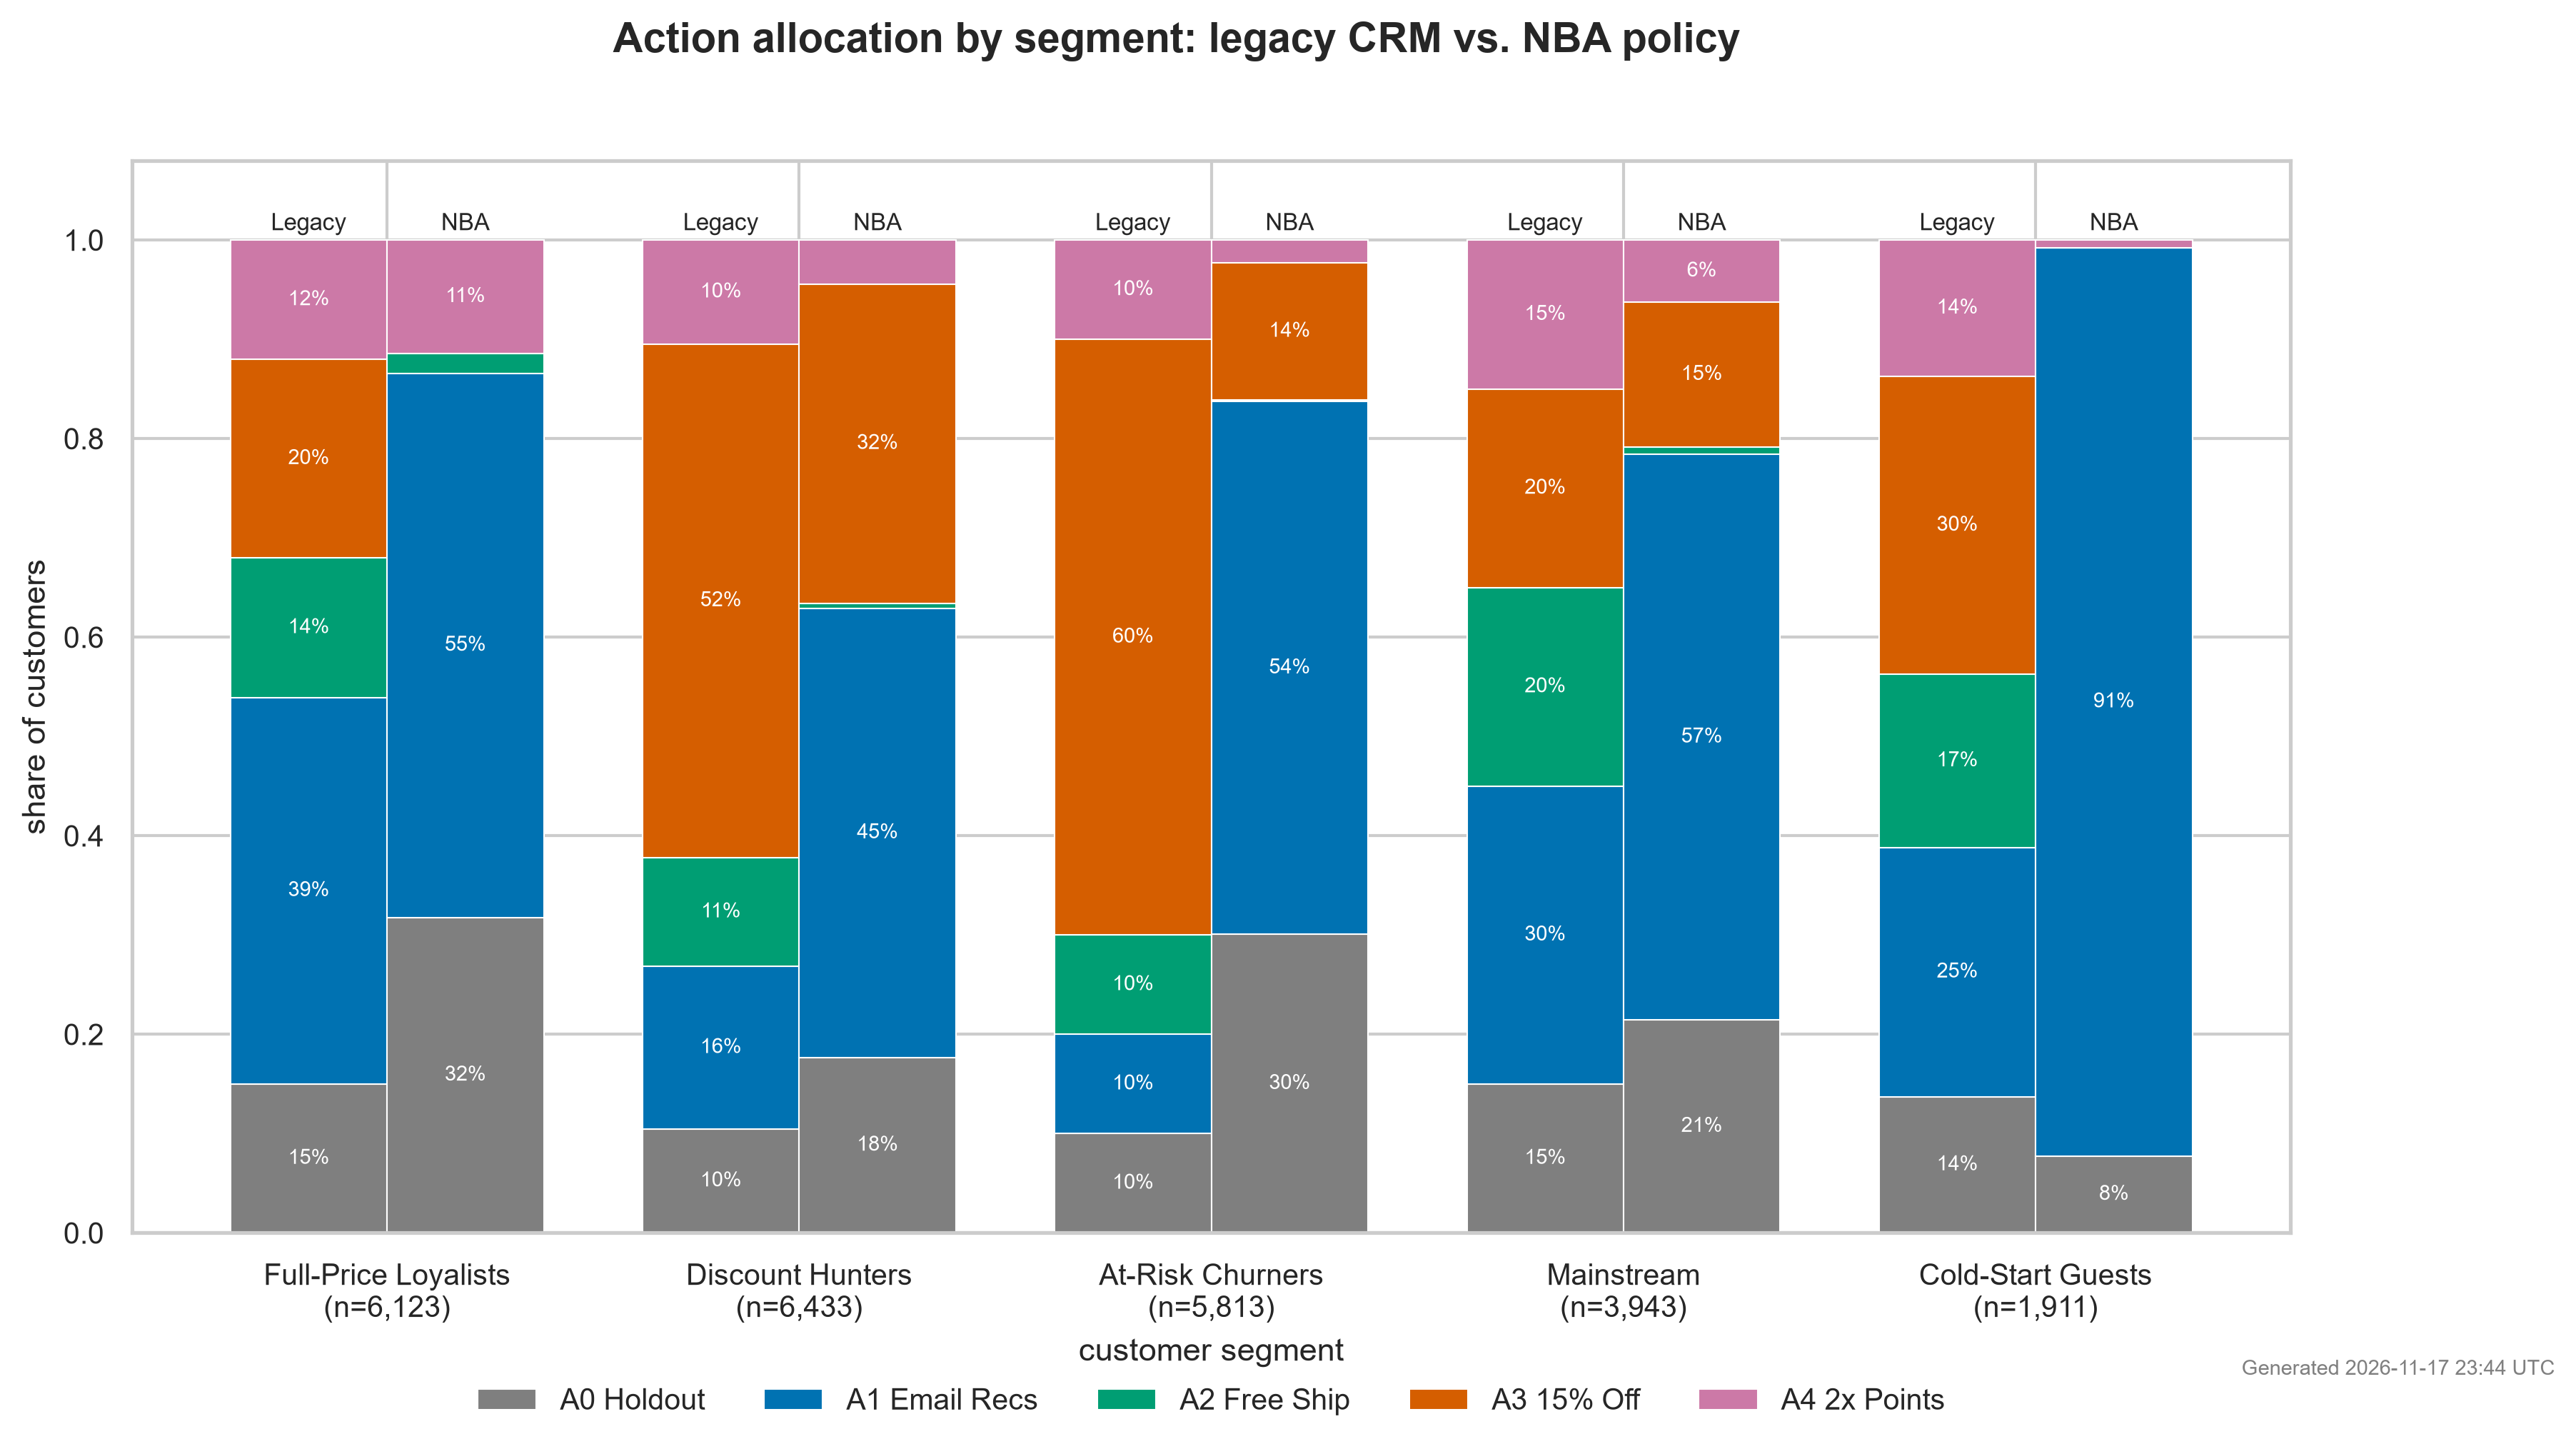

margin_vs_unsubscribe_pareto


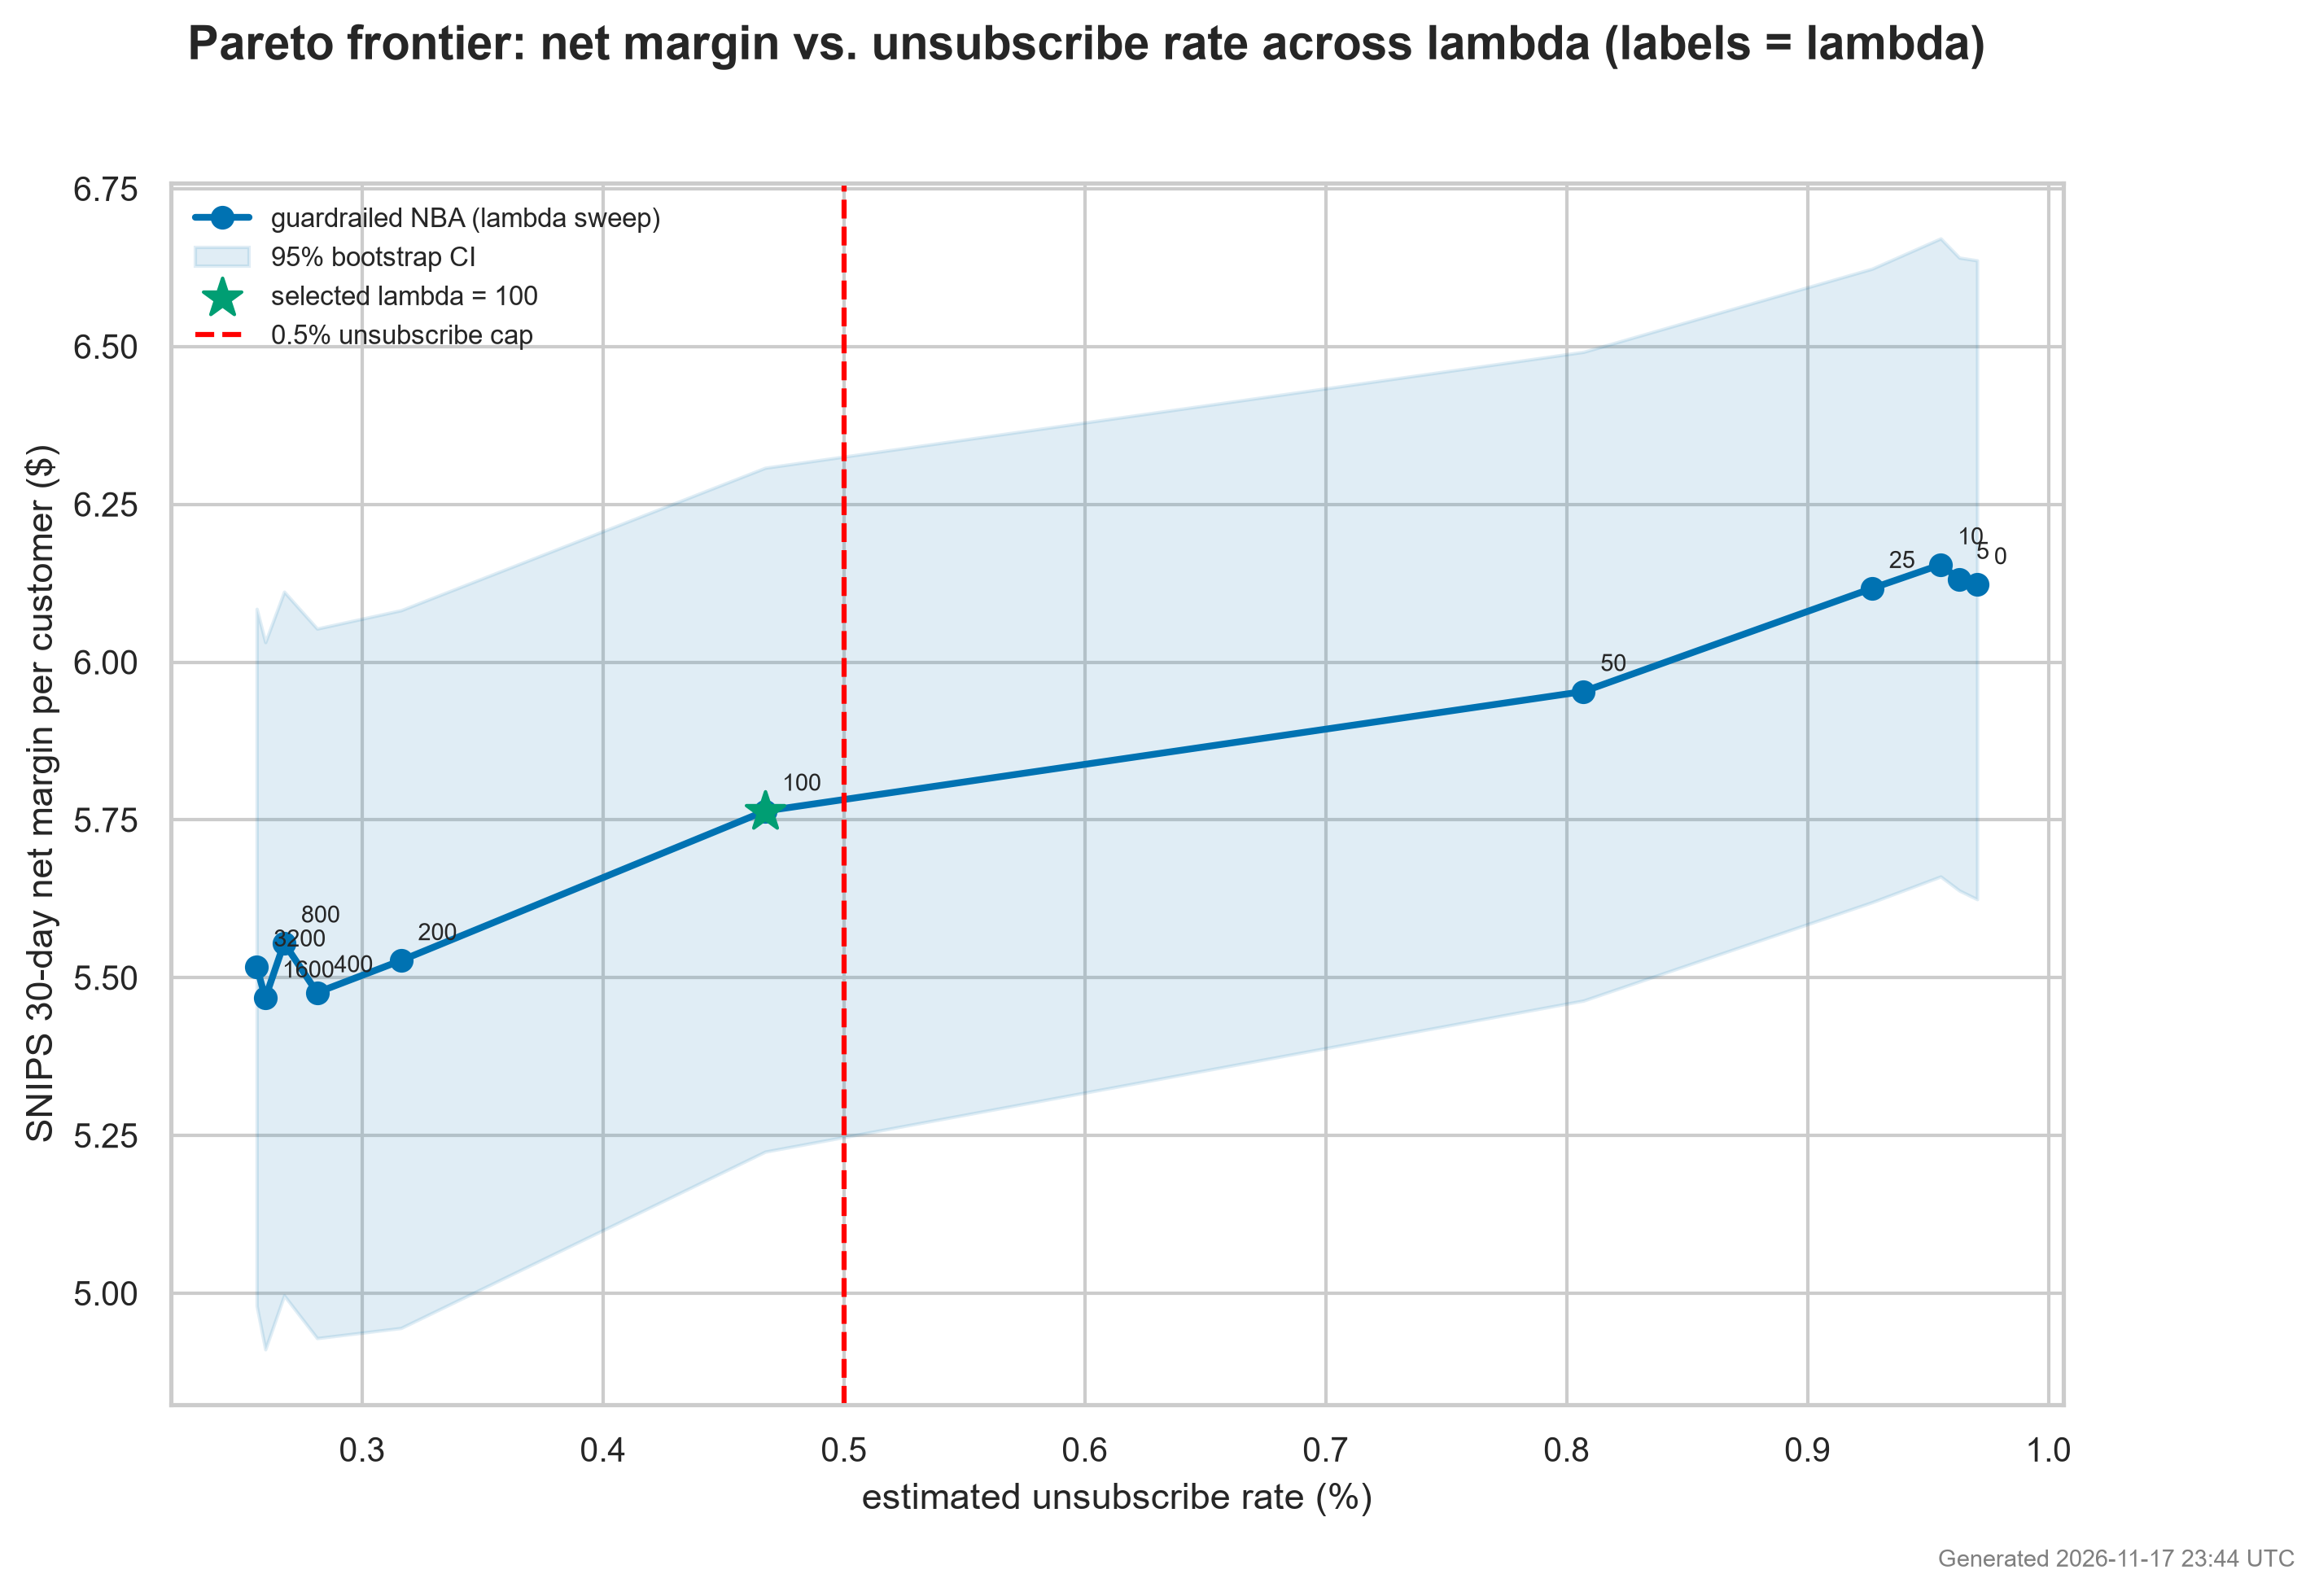

In [14]:
eval_plots.plot_policy_comparison(am, reports)
eval_plots.plot_allocation_by_segment(am, x_te, nba.actions)
eval_plots.plot_pareto(am, sweep, lam_star)
for name in ("policy_net_margin_comparison", "action_allocation_by_segment", "margin_vs_unsubscribe_pareto"):
    print(name); display(Image(filename=str(am.dir("comparison_plots") / f"{name}.png"), width=900))

## 6. Persist final configuration

In [15]:
update_manifest(am, risk_aversion_lambda=lam_star, holdout_metrics={
    **qini, **calib, "policy_snips_net_margin": {r.name.replace("\n", " "): r.value for r in reports},
    "lambda_sweep": sweep.round(5).to_dict(orient="records")})
import json
man = am.read_json("saved_models", "model_manifest.json")
print(json.dumps({k: man[k] for k in ("model_version", "training_timestamp", "risk_aversion_lambda", "action_costs", "cross_validation_metrics")}, indent=2))
print(sorted(p.relative_to(am.root).as_posix() for p in am.root.rglob("*") if p.is_file() and p.suffix in (".png", ".joblib", ".json")))

{
  "model_version": "nba-20261117T234417Z",
  "training_timestamp": "2026-11-17T23:44:17.697672+00:00",
  "risk_aversion_lambda": 100.0,
  "action_costs": {
    "0": 0.0,
    "1": 0.0,
    "2": 8.0,
    "3": 0.5,
    "4": 2.0
  },
  "cross_validation_metrics": {
    "propensity_logloss": 1.422289558534963,
    "propensity_auc_ovr": 0.6105710451546872,
    "margin_outcome_r2": 0.05502907441714552,
    "unsub_outcome_auc": 0.7015052907124003,
    "cv_folds": 3
  }
}
['api_request_response.png', 'comparison_plots/action_allocation_by_segment.png', 'comparison_plots/margin_vs_unsubscribe_pareto.png', 'comparison_plots/policy_net_margin_comparison.png', 'data_plots/feature_correlations_and_drift.png', 'data_plots/margin_and_return_distributions.png', 'data_plots/treatment_propensity_overlap.png', 'saved_models/baseline_purchase_model.joblib', 'saved_models/feature_transformer.joblib', 'saved_models/margin_uplift_model.joblib', 'saved_models/model_manifest.json', 'saved_models/unsub_uplift_

## Takeaways and caveats
* The guardrailed NBA beats the legacy CRM and both naive baselines in SNIPS net margin, while keeping the estimated unsubscribe rate under the 0.5% cap at the selected lambda.
* Naive propensity targeting concentrates on "Sure Things"; its true incremental value (oracle column, available only on synthetic data) is negative.
* CATE recovery is strong for the 15%-off action but weak for the small-effect actions (A1, A2, A4) at this sample size; confidence intervals on policy value overlap, so treat gaps as suggestive.
* The unsubscribe rate on the Pareto curve is a model-based estimate (events are too rare for stable SNIPS).